# Part 3 — The problem: iid sampling and simulation disagree
Paper Fig. 1 (top row), Eq. 7, §5.1, Two For One baseline. See [README.md](README.md).

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent            # notebooks live one level below the project root
sys.path.insert(0, str(ROOT))
import numpy as np, torch, matplotlib.pyplot as plt
torch.set_default_dtype(torch.float64)      # float64: the FP estimator uses finite differences with sigma=1e-4
torch.set_num_threads(8)
from scoremd import sde, models, losses, sampling, simulate, metrics, potentials, plotting, experiments as ex
%matplotlib inline

## 1. Figure 1, top row: Gaussian mixture trained with DSM only
Three panels: reference, iid samples `p(x)`, learned density `p₀(x) ∝ exp(log p_θ(x, 1e-5))`.

loaded gmm_diffusion_seed0.pt
mass of small mode: exact 0.200 | iid 0.191 | learned p0 0.091


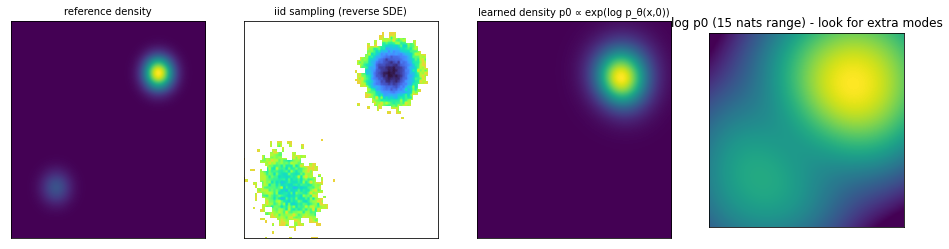

In [2]:
x, info = ex.load_system('gmm')
model = ex.get_model('gmm_diffusion')
samples = ex.iid_samples(model, n=20_000, steps=500)
R = [[-3.0, 1.6], [-3.0, 1.6]]   # normalised coords: small mode near (-1.94,-1.94), big mode near (0.49,0.49)
Xg, Yg, logp0 = metrics.grid_log_density(model.log_p, R, n=200)
_, _, logp_true = metrics.grid_log_density(lambda a, b: info['gmm'].log_p_t(a, b, info['shift'], info['scale']), R, n=200)
fig, ax = plt.subplots(1, 4, figsize=(16, 4))
plotting.density_image(ax[0], Xg, Yg, logp_true, 'reference density')
plotting.free_energy_hist(ax[1], samples, R, bins=80, title='iid sampling (reverse SDE)')
plotting.density_image(ax[2], Xg, Yg, logp0, 'learned density p0 ∝ exp(log p_θ(x,0))')
ax[3].imshow(logp0, origin='lower', extent=[-3.0, 1.6, -3.0, 1.6], cmap='viridis', vmin=logp0.max() - 15)
ax[3].set_title('log p0 (15 nats range) - look for extra modes'); ax[3].set_xticks([]); ax[3].set_yticks([])

def small_mode_mass(logd):
    p = np.exp(logd); return float(p[(Xg + Yg) < 0].sum() / p.sum())
print(f'mass of small mode: exact 0.200 | iid {float((samples.sum(1) < 0).double().mean()):.3f} | learned p0 {small_mode_mass(logp0):.3f}')

## 2. Where is the learned score wrong?
We know the exact diffused density, so we can measure the relative score error `‖s_θ − ∇log p_t‖ / ‖∇log p_t‖`
on noised data `x_t` for every `t`.

Text(0.5, 1.0, 'score error vs diffusion time (DSM-only model)')

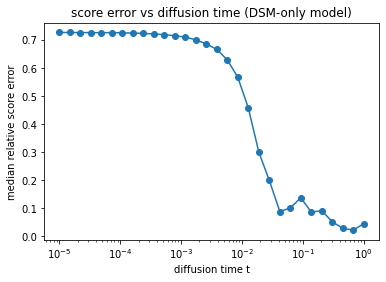

In [3]:
truth = models.AnalyticModel(lambda a, b: info['gmm'].log_p_t(a, b, info['shift'], info['scale']))
ts = torch.logspace(-5, 0, 30); err = []
for tv in ts:
    tt = torch.full((2000,), float(tv)); xt, _, _ = sde.perturb(x[:2000], tt)
    st, sm = truth.score(xt, tt), model.score(xt, tt)
    err.append(float(((sm - st).norm(dim=1) / st.norm(dim=1)).median()))
plt.semilogx(ts, err, 'o-'); plt.xlabel('diffusion time t'); plt.ylabel('median relative score error')
plt.title('score error vs diffusion time (DSM-only model)')

## 3. Müller–Brown: iid vs. simulation vs. Two For One
* **Diffusion (sim)**: Langevin with the force `s_θ(x, 1e-5)`
* **Two For One (sim)**: same model, force `s_θ(x, 0.02)` (Arts et al. 2023)

loaded mb_diffusion_seed0.pt
Diffusion iid              small basin 0.124   {'pmf': 3.514866734952879, 'js': 0.037013273158401534}
Diffusion sim (t=1e-5)     small basin 0.068   {'pmf': 5.878286722636023, 'js': 0.13395215265329102}
Two For One sim (t=0.02)   small basin 0.004   {'pmf': 5.357692941926316, 'js': 0.11254676906411622}
reference small basin 0.13691


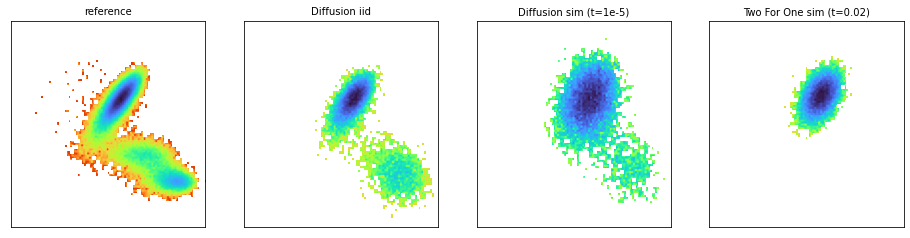

In [4]:
x, info = ex.load_system('mb'); rng = metrics.hist_range(x)
mb = ex.get_model('mb_diffusion')
iid = ex.iid_samples(mb, n=20_000)
sim, _ = ex.simulate_model(mb, x, t_eval=ex.T_EVAL)
sim_tfo, _ = ex.simulate_model(mb, x, t_eval=ex.T_TWO_FOR_ONE)
fig, ax = plt.subplots(1, 4, figsize=(16, 3.8))
for a, (name, s) in zip(ax, [('reference', x), ('Diffusion iid', iid), ('Diffusion sim (t=1e-5)', sim), ('Two For One sim (t=0.02)', sim_tfo)]):
    plotting.free_energy_hist(a, s, rng, title=name)
    if name != 'reference':
        print(f'{name:26s} small basin {ex.mb_small_basin_fraction(s, info):.3f}  ', ex.compare(s, x))
print('reference small basin', ex.mb_small_basin_fraction(x, info))

## 4. Two For One blurs the structure (analogue of Fig. 3 / Fig. 12)
`s_θ(x, 0.02)` is the score of the *noised* distribution, so simulated configurations are too spread out.
Here we look at the spread of `y` inside the deepest basin (in molecules: bond lengths become too broad).

Text(0.5, 1.0, 'Two For One adds noise to the structure')

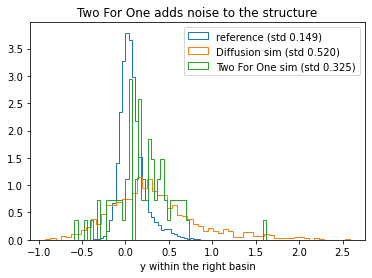

In [5]:
def basin_y(s):
    raw = s * info['scale'] + info['shift']; m = (raw[:, 0] > 0.3)
    return raw[m, 1].numpy()
for name, s in [('reference', x), ('Diffusion sim', sim), ('Two For One sim', sim_tfo)]:
    yb = basin_y(s); plt.hist(yb, 60, density=True, histtype='step', label=f'{name} (std {yb.std():.3f})')
plt.legend(); plt.xlabel('y within the right basin'); plt.title('Two For One adds noise to the structure')

**Take-away.** iid samples look right; the energy at `t ≈ 0` (and therefore MD with it) does not.
Evaluating at larger `t` hides the issue but blurs the structure. Part 4 diagnoses the cause via the Fokker–Planck equation.